# 1 · Ingesta de APIs Públicas Oficiales: Banco Mundial (WDI) y Open-Meteo (ERA5)

**Objetivo:** Construir una base de datos abierta, verificable y trazable para nuestro agente con herramientas (*Tool-Calling Agent*), combinando dos fuentes públicas oficiales sin credenciales:
1. **Banco Mundial (`api.worldbank.org/v2/`):** 8 indicadores macroeconómicos, energéticos y sociales (1990–2024) en **12 países** de América Latina y referencia global (`ECU`, `COL`, `PER`, `CHL`, `ARG`, `BRA`, `MEX`, `URY`, `CRI`, `BOL`, `PRY`, `USA`).
2. **Open-Meteo Historical Weather API (`archive-api.open-meteo.com/v1/archive`):** Series diarias reales (2020–2024, **21.924 registros diarios**) de temperatura media, máxima, mínima, precipitación acumulada, radiación solar y viento máximo para las **12 ciudades principales**.

> **Dos modos de datos.** Este notebook usa la *instantánea* versionada (`data/instantanea_*.json`): Banco Mundial 1990–2024 y clima 2020–2024. Esa ventana climática es una **decisión de diseño** para evaluar de forma reproducible, no un límite de Open-Meteo (su archivo ERA5 llega a 1940). Con `AGENTE_MODO_DATOS=vivo` las herramientas consultan las APIs por HTTP (`src/agente/clientes_api.py`, con caché en disco, pausas y reintentos) y aceptan clima desde 1940 y WDI desde 1960.

In [1]:
import json, sys, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))

from agente import config, datos
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

## 1.1 · Cobertura de los 8 indicadores oficiales del Banco Mundial (1990–2024)

In [2]:
bm = datos.cargar_instantanea_bm()
df_cobertura = pd.DataFrame(bm["resumen_cobertura"])
print(f"Total de observaciones anuales descargadas: {df_cobertura['n_observaciones'].sum():,}")

resumen_por_ind = (
    df_cobertura.groupby(["indicador", "codigo_bm"], as_index=False)
    .agg(
        paises_con_datos=("codigo_pais", "count"),
        observaciones_totales=("n_observaciones", "sum"),
        anio_min=("anio_min", "min"),
        anio_max=("anio_max", "max"),
        media_ultimo_valor=("ultimo_valor", "mean"),
    )
)
resumen_por_ind

Total de observaciones anuales descargadas: 3,178


,indicador,codigo_bm,paises_con_datos,observaciones_totales,anio_min,anio_max,media_ultimo_valor
0,crecimiento_pib_pct,NY.GDP.MKTP.KD.ZG,12,420,1990,2024,1.92
1,desempleo_pct,SL.UEM.TOTL.ZS,12,408,1991,2024,5.98
2,energias_renovables_pct,EG.FEC.RNEW.ZS,12,384,1990,2021,28.88
3,esperanza_vida_anios,SP.DYN.LE00.IN,12,420,1990,2024,77.04
4,indice_gini,SI.POV.GINI,12,336,1990,2024,44.23
5,inflacion_anual_pct,FP.CPI.TOTL.ZG,12,392,1990,2024,21.65
6,pib_per_capita_usd,NY.GDP.PCAP.CD,12,420,1990,2024,"18,203.37"
7,usuarios_internet_pct,IT.NET.USER.ZS,12,398,1990,2024,85.54


## 1.2 · Comparativa macroeconómica y social más reciente por país (Banco Mundial)

In [3]:
tabla_reciente = (
    df_cobertura.pivot(index=["codigo_pais", "pais"], columns="indicador", values="ultimo_valor")
    .reset_index()
    .sort_values("pib_per_capita_usd", ascending=False)
)
tabla_reciente

indicador,codigo_pais,pais,crecimiento_pib_pct,desempleo_pct,energias_renovables_pct,esperanza_vida_anios,indice_gini,inflacion_anual_pct,pib_per_capita_usd,usuarios_internet_pct
11,USA,Estados Unidos,2.79,4.02,10.90,78.89,41.80,2.95,"86,169.66",94.69
10,URY,Uruguay,3.33,8.21,57.80,78.29,40.00,4.85,"24,308.50",91.99
5,CRI,Costa Rica,4.08,6.94,34.20,81.00,45.80,-0.41,"18,853.28",87.17
3,CHL,Chile,2.81,8.72,24.20,81.36,43.00,4.30,"16,658.97",95.59
7,MEX,México,1.35,2.68,13.00,75.26,42.60,4.72,"13,988.04",83.12
0,ARG,Argentina,-1.34,7.15,9.20,77.54,42.40,219.88,"13,969.78",89.67
2,BRA,Brasil,3.42,6.80,46.50,76.02,50.30,4.37,"10,310.55",84.46
8,PER,Perú,3.52,5.20,30.60,77.94,40.10,2.01,"8,526.30",81.96
4,COL,Colombia,1.49,9.62,29.70,77.91,54.40,6.61,"7,951.09",79.35
6,ECU,Ecuador,-1.94,3.45,18.90,77.58,45.20,1.55,"6,826.53",77.17


## 1.3 · Series históricas de Open-Meteo (ERA5, 2020–2024) en las 12 ciudades

In [4]:
df_clima = datos.construir_dataframe_clima_anual()
resumen_ciudades = (
    df_clima.groupby(["ciudad", "codigo_pais", "altitud_m"], as_index=False)
    .agg(
        temp_media_c=("temp_media_c", "mean"),
        temp_max_extrema_c=("temp_max_c", "max"),
        temp_min_extrema_c=("temp_min_c", "min"),
        precipitacion_anual_mm=("precipitacion_mm", "mean"),
        radiacion_solar_mj_m2=("radiacion_solar_mj_m2", "mean"),
        viento_max_kmh=("viento_max_kmh", "max"),
        dias_lluvia_promedio=("dias_lluvia", "mean"),
    )
    .sort_values("precipitacion_anual_mm", ascending=False)
)
resumen_ciudades

,ciudad,codigo_pais,altitud_m,temp_media_c,temp_max_extrema_c,temp_min_extrema_c,precipitacion_anual_mm,radiacion_solar_mj_m2,viento_max_kmh,dias_lluvia_promedio
8,Quito,ECU,2850,11.90,22.90,3.00,"3,665.76",20.24,22.70,255.80
9,San José,CRI,1172,19.92,31.00,11.70,"3,445.50",18.82,25.80,239.60
0,Asunción,PRY,43,23.56,41.70,2.50,"1,413.38",18.58,41.90,107.80
11,São Paulo,BRA,760,19.39,38.40,1.20,"1,259.12",17.91,43.10,152.20
1,Bogotá,COL,2640,13.47,26.20,1.30,"1,082.88",20.01,25.10,198.40
3,Ciudad de México,MEX,2240,17.22,34.20,1.00,"1,062.12",22.22,38.50,135.20
4,Guayaquil,ECU,4,25.23,36.00,18.40,957.66,18.18,26.40,98.80
2,Buenos Aires,ARG,25,17.57,38.90,-1.40,894.10,17.93,52.70,82.20
7,Montevideo,URY,43,17.03,38.90,1.10,881.36,17.63,62.90,99.40
5,La Paz,BOL,3640,10.24,24.60,-4.90,658.52,23.70,32.40,117.60


## 1.4 · Visualización conjunta de los catálogos económicos y climáticos

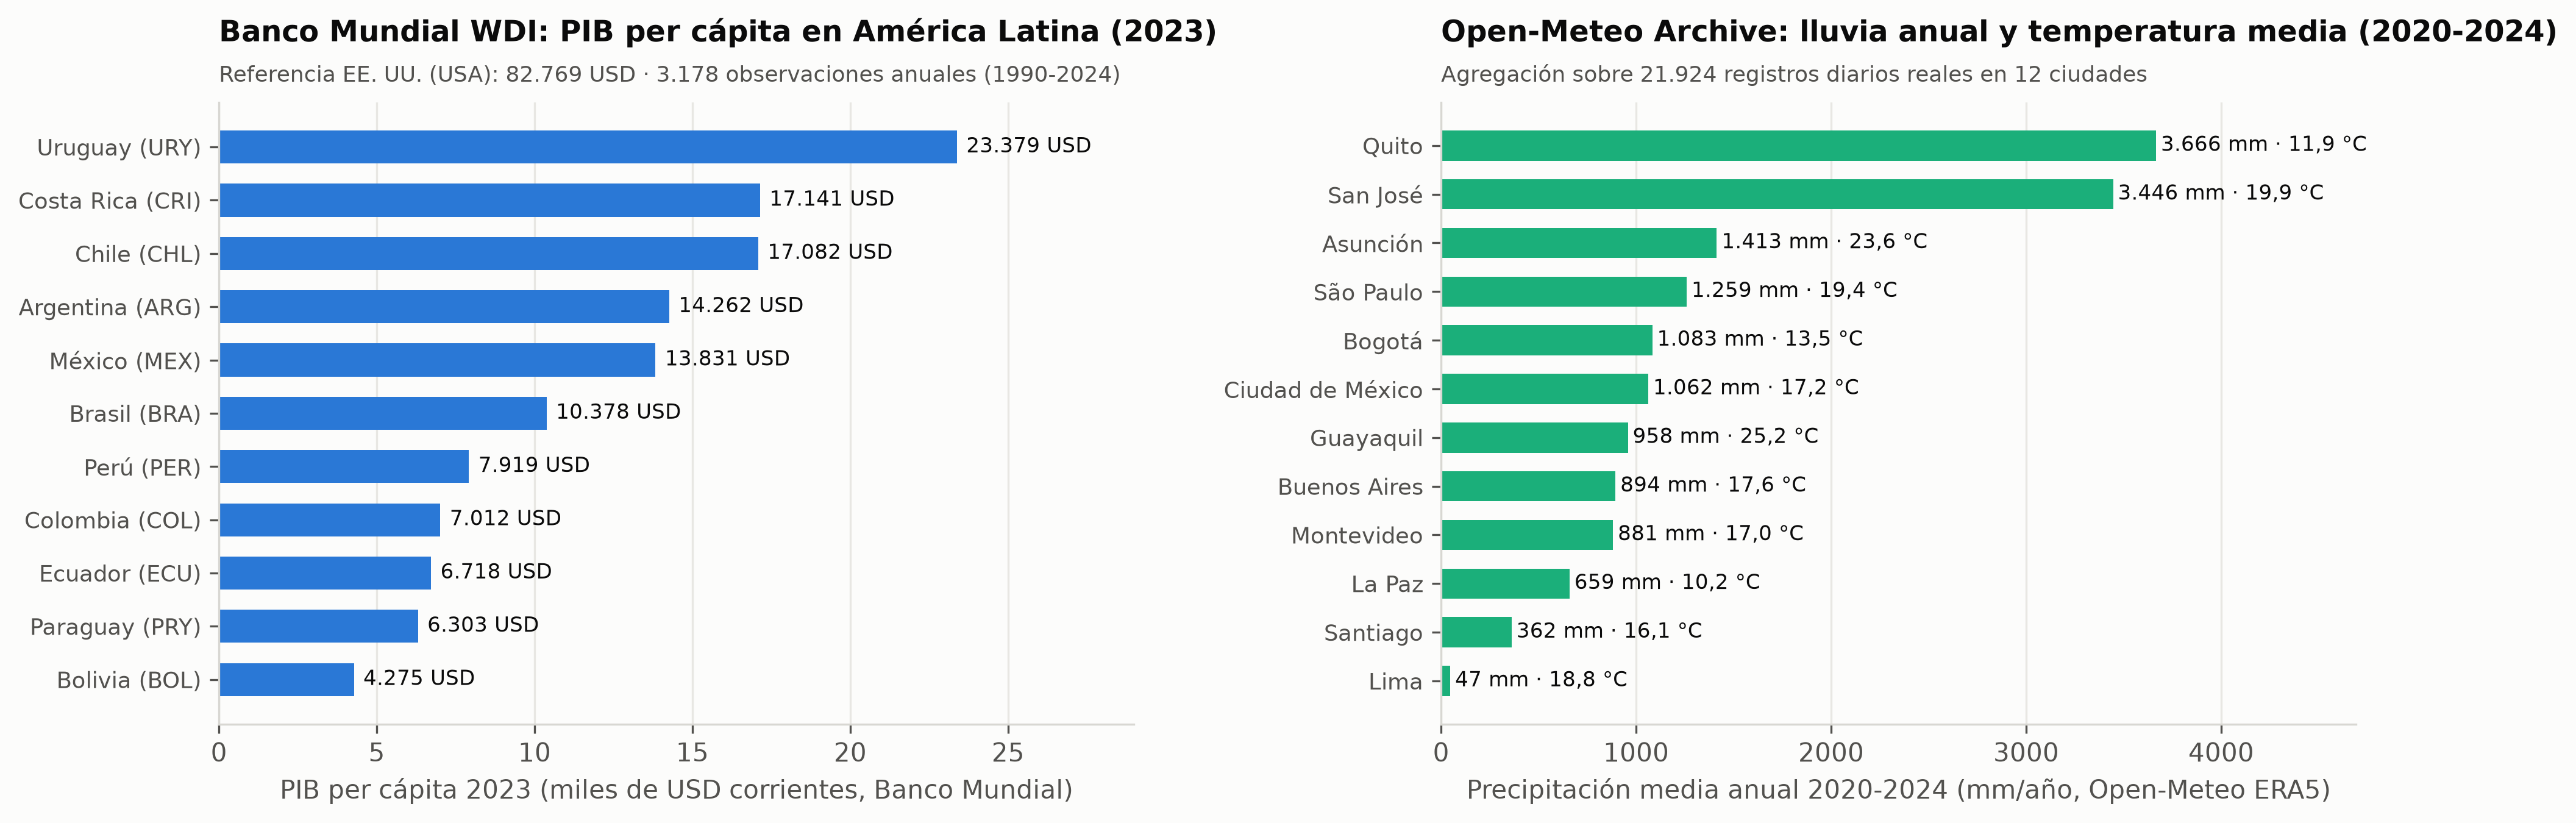

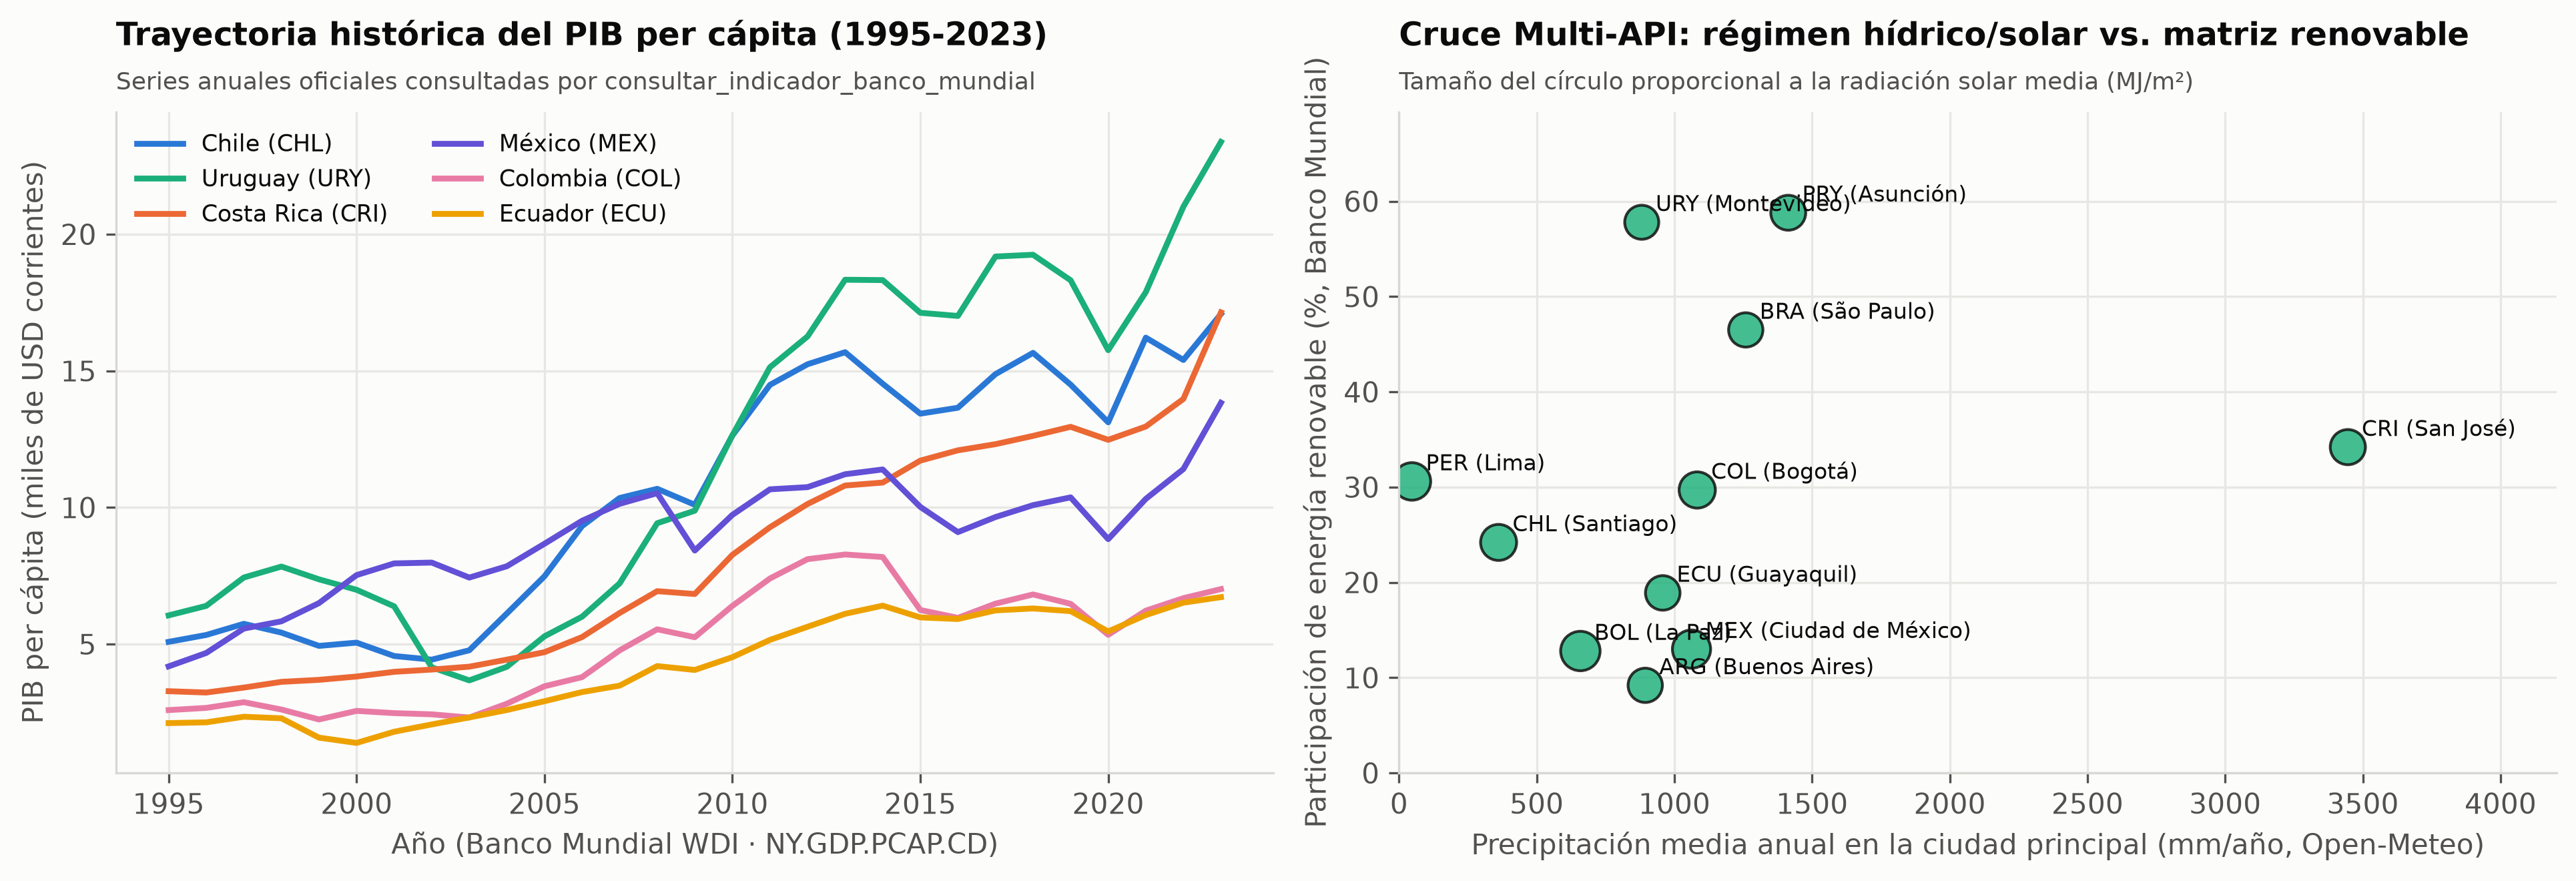

In [5]:
display(Image(filename=str(RAIZ / "reports" / "figures" / "01_cobertura_datos_banco_mundial_y_clima.png")))
display(Image(filename=str(RAIZ / "reports" / "figures" / "07_cruce_real_clima_economia_latam.png")))